In [1]:
import sys, json; sys.path.insert(0, '..')
import pandas as pd, numpy as np
from IPython.display import Image, display
from src import preprocessing as pp, feature_engineering as fe, pipeline as P
from src.config import *
pd.set_option('display.width', 200); pd.set_option('display.max_columns', 40)
def show(name, w=800): display(Image(filename=str(FIG / name), width=w))

/usr/local/lib/python3.12/dist-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


# 10 Evaluation
Accuracy, macro precision/recall/F1, specificity, ROC-AUC (one-vs-rest macro), PR-AUC (macro), Brier, calibration, bootstrap CIs.

In [2]:
pd.read_csv(TAB/'model_comparison_A_characteristics.csv').round(3).T

,0,1,2,3,4,5,6,7
Model,Logistic Regression,Decision Tree,Random Forest,XGBoost,Majority-class baseline,Hybrid: Soft Voting,Hybrid: Weighted Voting,Hybrid: Stacking
Accuracy,0.387,0.382,0.391,0.396,0.333,0.382,0.382,0.387
Balanced Acc.,0.387,0.382,0.391,0.396,0.333,0.382,0.382,0.387
Precision (macro),0.384,0.385,0.372,0.391,0.111,0.373,0.371,0.348
Recall (macro),0.387,0.382,0.391,0.396,0.333,0.382,0.382,0.387
Specificity (macro),0.693,0.691,0.696,0.698,0.667,0.691,0.691,0.693
F1 (macro),0.384,0.383,0.375,0.393,0.167,0.373,0.372,0.356
F1 (weighted),0.384,0.383,0.375,0.393,0.167,0.373,0.372,0.356
ROC-AUC (OvR macro),0.58,0.544,0.591,0.568,0.5,0.581,0.581,0.594
PR-AUC (macro),0.408,0.376,0.427,0.404,0.333,0.418,0.418,0.431


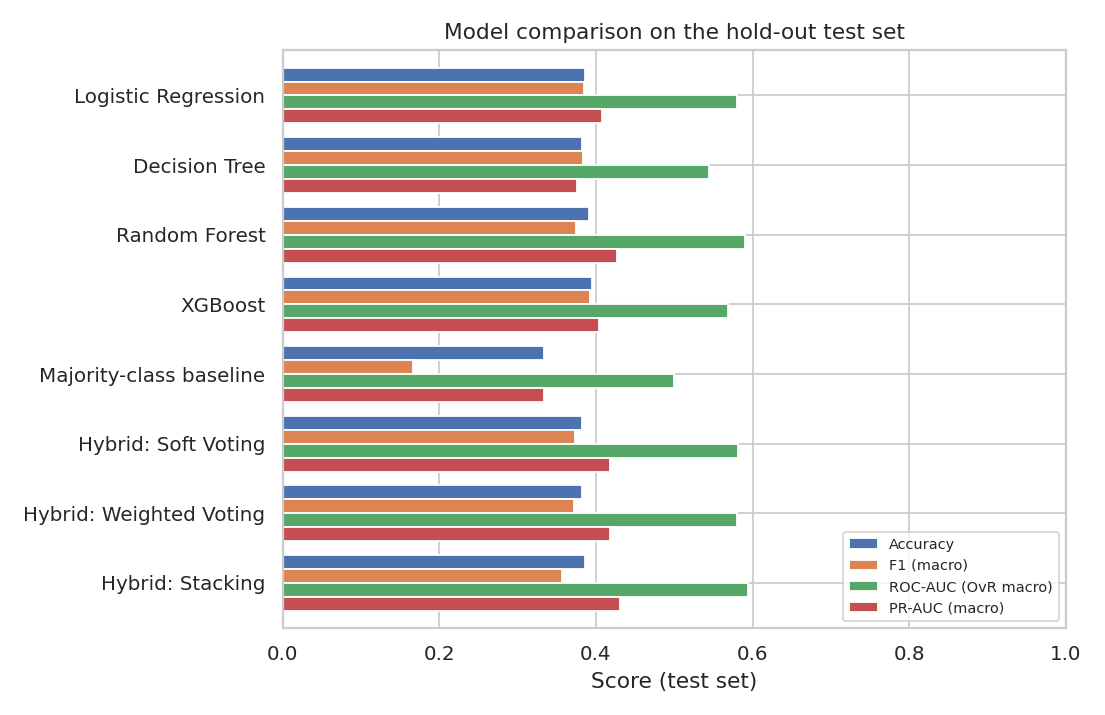

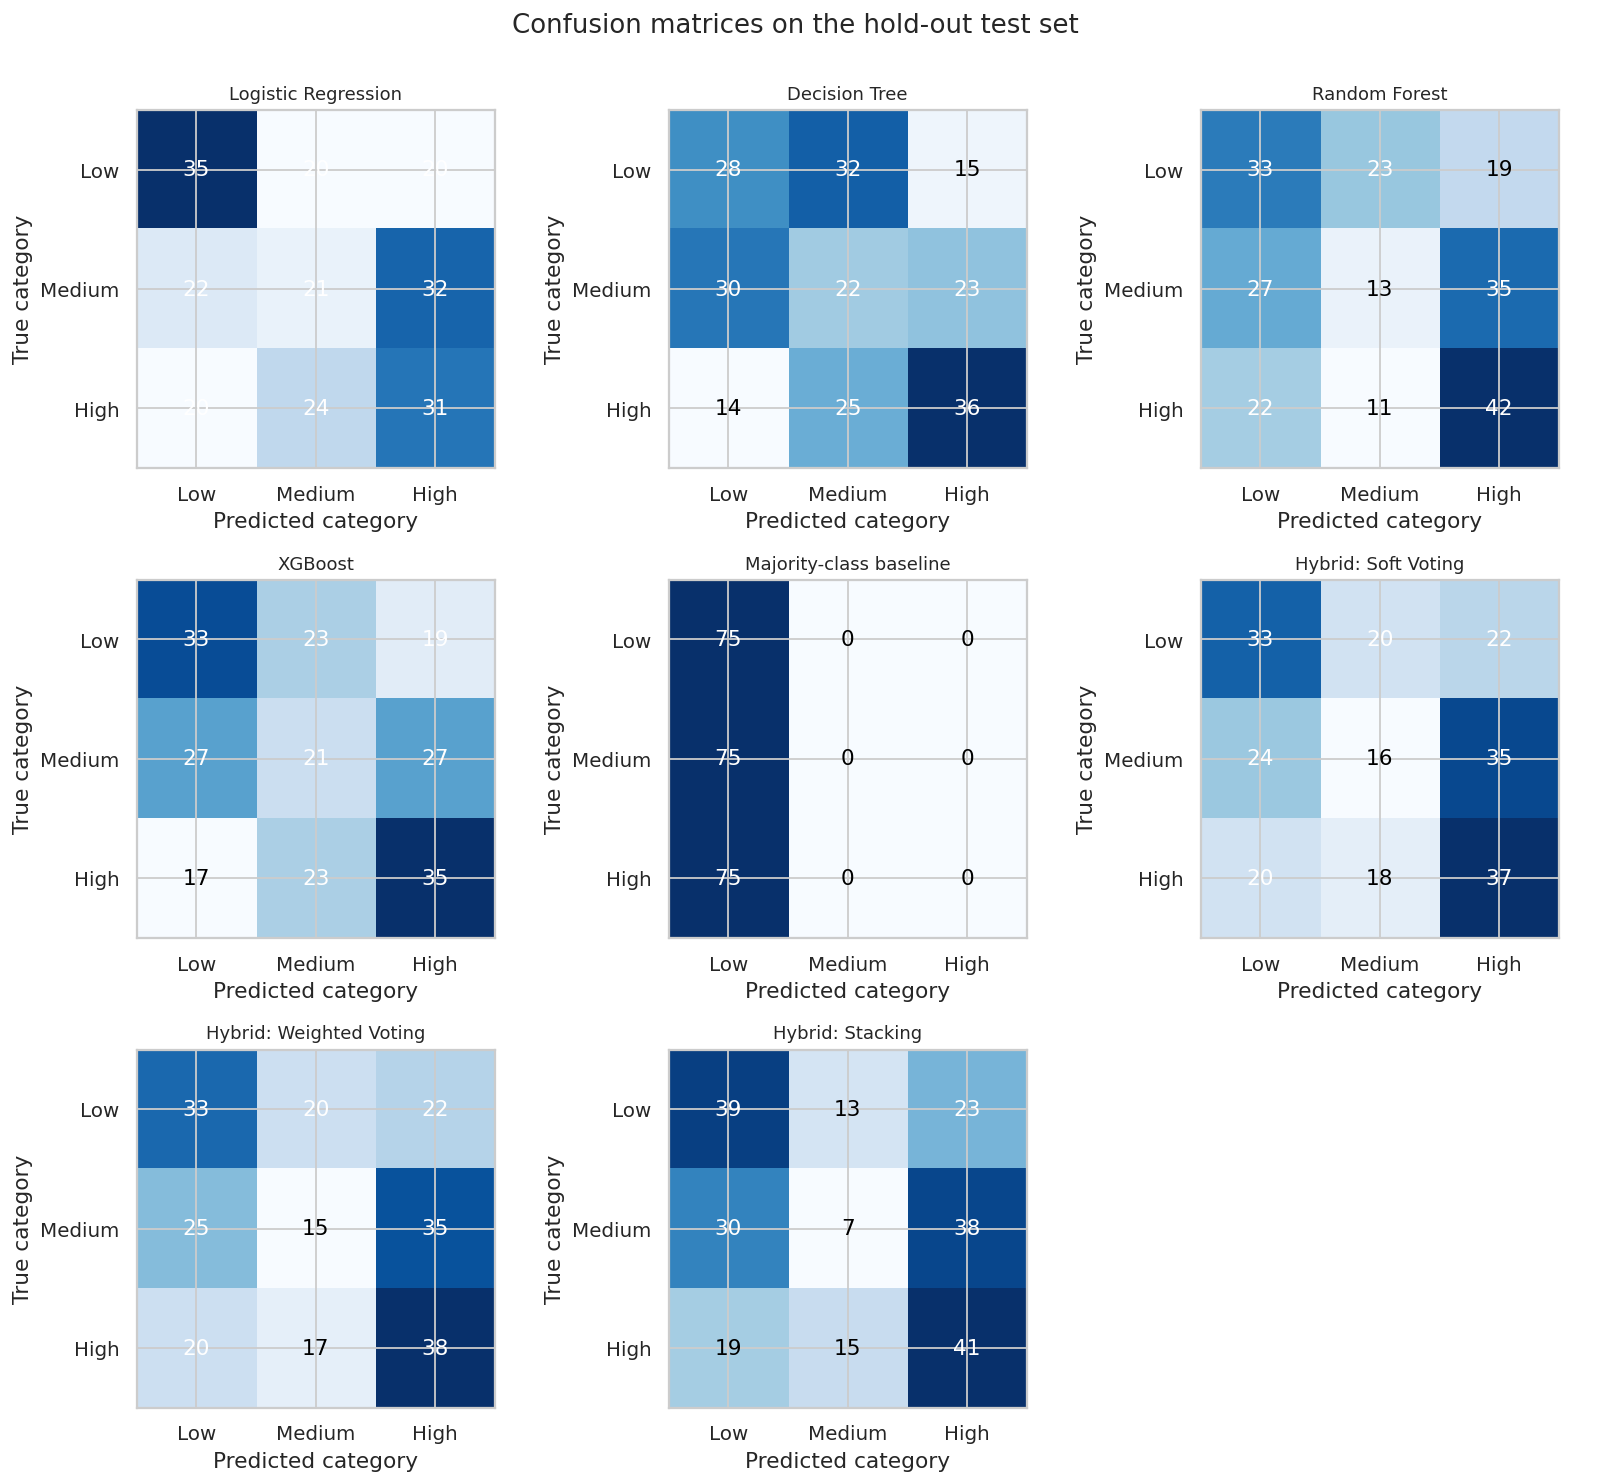

In [3]:
show('fig14_model_comparison.png', 700); show('fig11_confusion_matrices.png')

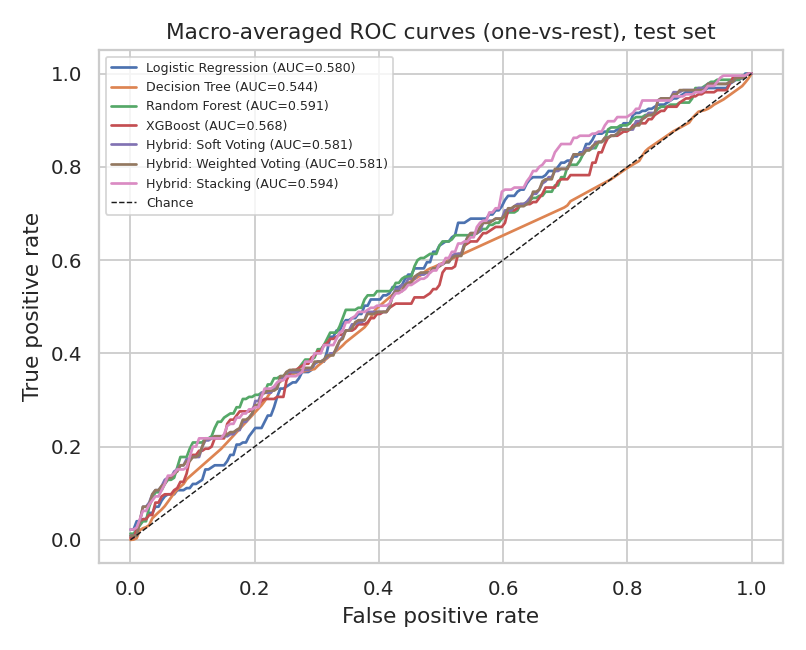

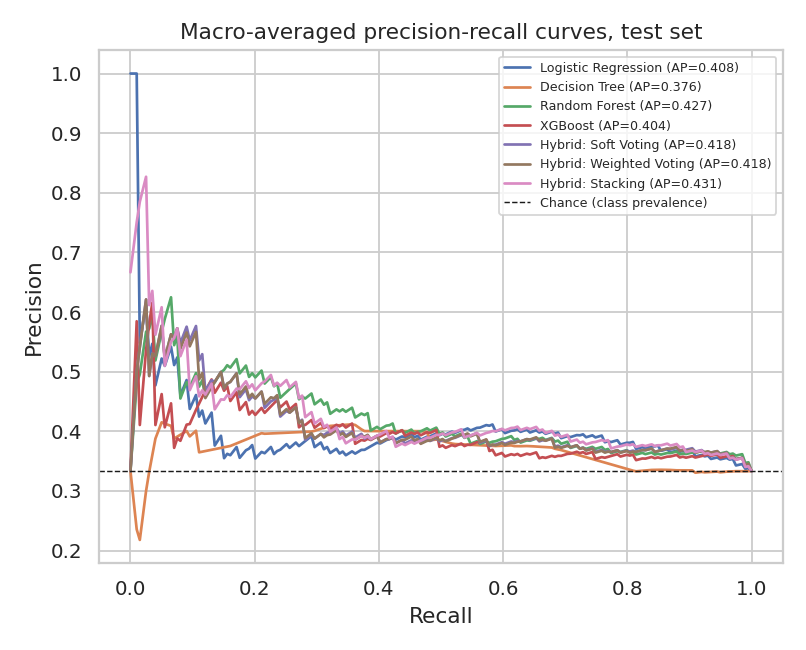

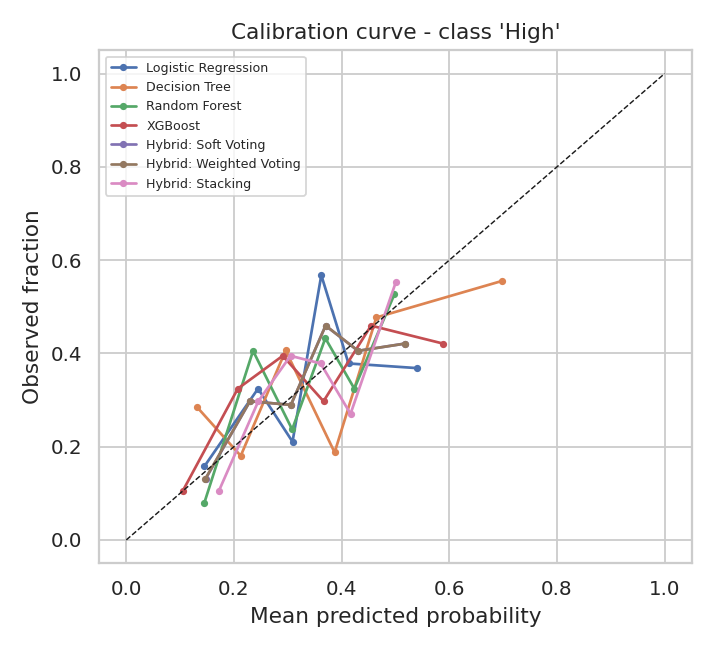

In [4]:
show('fig12_roc_curves.png', 500); show('fig13_pr_curves.png', 500); show('fig15_calibration_high.png', 450)

### Diagnostic statistics (associations, not causation)

In [5]:
pd.read_csv(TAB/'diagnostic_tests.csv').round(4)

,test,statistic,p_value,effect_size,effect_name
0,Kruskal-Wallis: index ~ Ownership Type,26.2361,0.0000,0.0208,epsilon-squared
1,Kruskal-Wallis: index ~ CMS Region,55.3199,0.0000,0.0416,epsilon-squared
2,Chi-square: Ownership Type x category,22.4483,0.0010,0.1000,Cramer's V
3,Chi-square: CMS Region x category,61.5308,0.0000,0.1655,Cramer's V
4,Spearman: index ~ facility_age_years,0.0610,0.0408,0.0610,rho
5,Spearman: index ~ n_irf_in_state,-0.1497,0.0000,-0.1497,rho
6,Spearman: index ~ log_eligible_stays,0.0357,0.2321,0.0357,rho
7,Spearman: index ~ log_mspb_episodes,0.0111,0.7140,0.0111,rho
8,Spearman: index ~ log_function_cases,0.0343,0.2503,0.0343,rho
9,"Mann-Whitney: index by name_has_rehab (n1=525,...",148472.0000,0.1169,-0.0542,rank-biserial


In [6]:
pd.read_csv(TAB/'ownership_pairwise.csv').round(4)

,pair,median_a,median_b,p_raw,p_bonferroni
0,For profit vs Non-profit,48.4370,52.1452,0.0000,0.0000
1,For profit vs Government,48.4370,50.5099,0.0226,0.0677
2,Non-profit vs Government,52.1452,50.5099,0.8171,1.0000


### Leakage check

In [7]:
print('CV accuracy when the index measures themselves are used as features (leakage demo, NOT a result):', json.load(open(OUT/'results.json'))['leakage_demo_cv_accuracy_index_measures_as_features'])

CV accuracy when the index measures themselves are used as features (leakage demo, NOT a result): 0.7934007936507936
